### **00. Import Libs and the DataSet**

In [1]:
#Import Libs
import pandas as pd
import numpy as np

In [2]:
#Import Specific Libs
from scipy import stats
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import (LabelEncoder, OrdinalEncoder, OneHotEncoder, TargetEncoder, StandardScaler, MinMaxScaler, RobustScaler,
                                   MaxAbsScaler, Normalizer, PowerTransformer, QuantileTransformer, KBinsDiscretizer, PolynomialFeatures, FunctionTransformer)
from sklearn.impute import SimpleImputer, KNNImputer, MissingIndicator
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict, cross_validate
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.neighbors import KNeighborsClassifier, LocalOutlierFactor, NearestNeighbors
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif, mutual_info_classif
from sklearn.decomposition import PCA
from sklearn.utils import resample
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, matthews_corrcoef, confusion_matrix)
from IPython.display import display

In [3]:
#Import the Graphic Libs
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
#Ignore Error Message
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=ConvergenceWarning)

In [5]:
#Import Dataframe from Github
df = pd.read_csv('https://raw.githubusercontent.com/jrafa1607/DataScience-ML-AI/main/-%20Datasets/credit_data.csv')

In [6]:
#Define New Attributes Names
df.columns = ['id', 'income', 'age', 'loan', 'result']
df.head(3)

,id,income,age,loan,result
0,1,66155.925095,59.017015,8106.532131,0
1,2,34415.153966,48.117153,6564.745018,0
2,3,57317.170063,63.108049,8020.953296,0


In [7]:
#Set the Seed and the Cross-Validation Used to Measure the Quality
SEED = 42
np.random.seed(SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
num_cols = ['income', 'age', 'loan']

### **01. Data Inspection ( Quality Report )**

Before fixing anything, **measure** how dirty the data is. The same report is used again at the end, so we can see the improvement.

In [8]:
#Show the Dataframe Info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   id      2000 non-null   int64  
 1   income  2000 non-null   float64
 2   age     1997 non-null   float64
 3   loan    2000 non-null   float64
 4   result  2000 non-null   int64  
dtypes: float64(3), int64(2)
memory usage: 78.3 KB


In [9]:
#Show the Descriptive Statistics
df.describe().round(2)

,id,income,age,loan,result
count,2000.00,2000.00,1997.00,2000.00,2000.00
mean,1000.50,45331.60,40.81,4444.37,0.14
std,577.49,14326.33,13.62,3045.41,0.35
min,1.00,20014.49,-52.42,1.38,0.00
25%,500.75,32796.46,28.99,1939.71,0.00
50%,1000.50,45789.12,41.32,3974.72,0.00
75%,1500.25,57791.28,52.59,6432.41,0.00
max,2000.00,69995.69,63.97,13766.05,1.00


In [10]:
#Check the Total of Null Values in the Database
df.isnull().sum()

,0
id,0
income,0
age,3
loan,0
result,0


In [11]:
#Details for the Null Values
df.loc[pd.isnull(df['age'])]

,id,income,age,loan,result
28,29,59417.805406,NaN,2082.625938,0
30,31,48528.852796,NaN,6155.784670,0
31,32,23526.302555,NaN,2862.010139,0


In [12]:
#Detecting Negative Values in the Dataframe ( LT = Lower Than... )
print(df.lt(0).sum())

id        0
income    0
age       3
loan      0
result    0
dtype: int64


In [13]:
#Check the Negative Values
df[df['age'] < 0]

,id,income,age,loan,result
15,16,50501.726689,-28.218361,3977.287432,0
21,22,32197.620701,-52.423280,4244.057136,0
26,27,63287.038908,-36.496976,9595.286289,0


In [14]:
#Check the Valid Ranges ( Domain Rules: Negative is Not the Only Invalid Value )
valid_ranges = {'income': (0, None), 'age': (18, 100), 'loan': (0, None)}

def check_ranges(data, ranges):
    rows = {}
    for col, (low, high) in ranges.items():
        invalid = pd.Series(False, index=data.index)
        if low is not None:
            invalid |= data[col] < low
        if high is not None:
            invalid |= data[col] > high
        rows[col] = {'min_allowed': low, 'max_allowed': high, 'invalid_rows': int(invalid.sum()), 'invalid_%': round(invalid.mean() * 100, 3)}
    return pd.DataFrame(rows).T

check_ranges(df, valid_ranges)

,min_allowed,max_allowed,invalid_rows,invalid_%
income,0.0,NaN,0.0,0.00
age,18.0,100.0,3.0,0.15
loan,0.0,NaN,0.0,0.00


In [15]:
#Create the Quality Report ( One Column of Metrics per Dataframe )
def quality_report(data, name='dataframe', exclude=('id',)):
    id_cols = [c for c in exclude if c in data.columns]
    numeric = data.select_dtypes(include='number').drop(columns=id_cols)
    return pd.Series({'rows': len(data), 'columns': data.shape[1],
                      'null_cells': int(data.isnull().sum().sum()), 'null_%': round(data.isnull().sum().sum() / data.size * 100, 3),
                      'negative_values': int((numeric < 0).sum().sum()),
                      'duplicated_rows ( ignoring id )': int(data.drop(columns=id_cols).duplicated().sum()),
                      'non_numeric_columns': int(data.shape[1] - data.select_dtypes(include='number').shape[1]),
                      'max_abs_skewness': round(numeric.skew().abs().max(), 2),
                      'memory_kb': round(data.memory_usage(deep=True).sum() / 1024, 1)}, name=name)

report_raw = quality_report(df, 'raw')
report_raw

,raw
rows,2000.00
columns,5.00
null_cells,3.00
null_%,0.03
negative_values,3.00
duplicated_rows ( ignoring id ),0.00
non_numeric_columns,0.00
max_abs_skewness,2.06
memory_kb,78.30


### **02. Fix Duplicates and Data Types**

In [16]:
#Check the Duplicated Rows ( All the Attributes and Ignoring the id )
print('Duplicated rows ( all attributes ):', df.duplicated().sum())
print('Duplicated rows ( ignoring id ):', df.drop(columns='id').duplicated().sum())
print('Duplicated id:', df['id'].duplicated().sum())

Duplicated rows ( all attributes ): 0
Duplicated rows ( ignoring id ): 0
Duplicated id: 0


In [17]:
#Option 01 - Remove the Duplicated Rows ( Ignoring the id )
df_unique = df.drop_duplicates(subset=[col for col in df.columns if col != 'id'])

#Metrics ( Rows Removed and Class Balance Kept )
print('Rows removed:', len(df) - len(df_unique), '| Positive rate before / after (%):', round(df['result'].mean() * 100, 2), '/', round(df_unique['result'].mean() * 100, 2))

Rows removed: 0 | Positive rate before / after (%): 14.15 / 14.15


In [18]:
#Option 02 - Convert the Data Types ( Smaller Types Use Less Memory )
df_types = df.copy()
df_types['id'] = df_types['id'].astype('int32')
df_types['result'] = df_types['result'].astype('int8')
for col in num_cols:
    df_types[col] = df_types[col].astype('float32')
print(df_types.dtypes)

#Metrics ( Memory Saved and Precision Lost )
before, after = df.memory_usage(deep=True).sum() / 1024, df_types.memory_usage(deep=True).sum() / 1024
relative_error = ((df[num_cols] - df_types[num_cols].astype('float64')).abs() / df[num_cols].abs()).max().max()
print('\nMemory (KB):', round(before, 1), '->', round(after, 1), '| Saved (%):', round((1 - after / before) * 100, 1), '| Maximum relative error of float32:', f'{relative_error:.2e}')

id          int32
income    float32
age       float32
loan      float32
result       int8
dtype: object

Memory (KB): 78.3 -> 33.3 | Saved (%): 57.4 | Maximum relative error of float32: 5.89e-08


### **03. Fix Negative Values**

First decide if the negative value is **valid** ( a bank balance can be negative ) or **invalid** ( an age can not ). Here, the 3 negative ages are invalid. The options below create a new dataframe in each example, so the original `df` is not changed.

In [19]:
#Option 01 - Remove the Attribute from Database
df_test = df.drop(['age'], axis=1)
print(df_test.shape)

(2000, 4)


In [20]:
#Option 02 - Remove the Lines from Database
df_test = df.drop(df[df['age'] < 0].index)
print(df_test.shape)

(1997, 5)


In [21]:
#Option 03 - Replace for the Mean of Positive Values
df_test = df.copy()
mean_age = df_test['age'][df_test['age'] > 0].mean()
print(mean_age, "\n")

#Replace the Negative Values
df_test.loc[df_test['age'] < 0, 'age'] = mean_age
print(df_test.lt(0).sum())

40.92770044906149 

id        0
income    0
age       0
loan      0
result    0
dtype: int64


In [22]:
#Option 04 - Replace for the Median of Positive Values ( Not Affected by Extreme Values )
df_test = df.copy()
df_test.loc[df_test['age'] < 0, 'age'] = df_test['age'][df_test['age'] > 0].median()
print(df_test.lt(0).sum())

id        0
income    0
age       0
loan      0
result    0
dtype: int64


In [23]:
#Option 05 - Absolute Value ( Use Only if the Negative Sign is a Typing Error )
df_test = df.copy()
df_test['age'] = df_test['age'].abs()
print(df_test.loc[[15, 21, 26], 'age'])

15    28.218361
21    52.423280
26    36.496976
Name: age, dtype: float64


In [24]:
#Option 06 - Clip to the Minimum Valid Value ( Every Invalid Age Becomes 18 )
df_test = df.copy()
df_test['age'] = df_test['age'].clip(lower=valid_ranges['age'][0])
print(df_test.loc[[15, 21, 26], 'age'])

15    18.0
21    18.0
26    18.0
Name: age, dtype: float64


In [25]:
#Option 07 [Recommended] - Convert the Negative Values to Null and Fix Everything in the Null Values Step
#Attention! Negative and null values are the same problem: a value that we do not trust. Converting to null lets ONE method ( Section 04 ) fix both
df_test = df.copy()
df_test.loc[df_test['age'] < 0, 'age'] = np.nan
print(df_test['age'].isnull().sum())

6


In [26]:
#Function to Fix the Negative Values ( All the Options in One Place )
def fix_negative_values(data, columns, method='nan', lower=0):
    out = data.copy()
    for col in columns:
        negative = out[col] < 0
        if method == 'drop':
            out = out[~negative]
        elif method == 'nan':
            out.loc[negative, col] = np.nan
        elif method == 'mean':
            out.loc[negative, col] = out.loc[~negative, col].mean()
        elif method == 'median':
            out.loc[negative, col] = out.loc[~negative, col].median()
        elif method == 'abs':
            out.loc[negative, col] = out.loc[negative, col].abs()
        elif method == 'clip':
            out[col] = out[col].clip(lower=lower)
        else:
            raise ValueError('Unknown method: ' + method)
    return out

In [27]:
#Compare the Options ( Metrics of the Quality of Each Fix )
positive_ages = df['age'][df['age'] > 0]
rows = {}
for method in ['drop', 'nan', 'mean', 'median', 'abs', 'clip']:
    fixed = fix_negative_values(df, ['age'], method, lower=18)
    rows[method] = {'rows': len(fixed), 'negatives_left': int((fixed['age'] < 0).sum()), 'nulls_in_age': int(fixed['age'].isnull().sum()),
                    'age_mean': fixed['age'].mean(), 'age_std': fixed['age'].std(),
                    'KS_vs_valid_ages': stats.ks_2samp(positive_ages, fixed['age'].dropna()).statistic,
                    'positive_rate_%': fixed['result'].mean() * 100}
pd.DataFrame(rows).T.round(4)

,rows,negatives_left,nulls_in_age,age_mean,age_std,KS_vs_valid_ages,positive_rate_%
drop,1997.0,0.0,3.0,40.9277,13.2718,0.0000,14.1713
nan,2000.0,0.0,6.0,40.9277,13.2718,0.0000,14.1500
mean,2000.0,0.0,3.0,40.9277,13.2618,0.0008,14.1500
median,2000.0,0.0,3.0,40.9284,13.2618,0.0008,14.1500
abs,2000.0,0.0,3.0,40.9249,13.2677,0.0004,14.1500
clip,2000.0,0.0,3.0,40.8933,13.2915,0.0015,14.1500


In [28]:
#Apply the Recommended Option ( Negative Values to Null )
df_neg = fix_negative_values(df, ['age'], method='nan')

#Metrics ( No Negative Values Left and Nothing Else Changed )
print('Negative values left:', int((df_neg[num_cols] < 0).sum().sum()), '| Null ages now:', df_neg['age'].isnull().sum(), '| Other columns unchanged:', df_neg[['id', 'income', 'loan', 'result']].equals(df[['id', 'income', 'loan', 'result']]))

Negative values left: 0 | Null ages now: 6 | Other columns unchanged: True


### **04. Fix Null Values**

| Option | Idea | Attention |
|---|---|---|
| Remove the attribute | Drops the whole column | Loses all the information of the column |
| Remove the rows | Drops the rows with nulls | Loses data: ok only if there are few nulls |
| Mean / median / mode / constant | Same value for every null | Reduces the variance of the column |
| Group value | Value of the group the row belongs to | Needs a good group |
| KNN / Iterative imputer | Predicts the null from the other attributes | Needs scaled data, is slower |
| Missing indicator | Adds a 0/1 column saying where the null was | Keeps the information that the value was missing |

In [29]:
#Check the Total of Null Values in the Database After Fix the Negative Values
df_neg.isnull().sum()

,0
id,0
income,0
age,6
loan,0
result,0


In [30]:
#Details for the Null Values
df_neg.loc[pd.isnull(df_neg['age'])]

,id,income,age,loan,result
15,16,50501.726689,NaN,3977.287432,0
21,22,32197.620701,NaN,4244.057136,0
26,27,63287.038908,NaN,9595.286289,0
28,29,59417.805406,NaN,2082.625938,0
30,31,48528.852796,NaN,6155.784670,0
31,32,23526.302555,NaN,2862.010139,0


In [31]:
#Percentage of Null Values per Attribute
(df_neg.isnull().mean() * 100).round(3)

,0
id,0.0
income,0.0
age,0.3
loan,0.0
result,0.0


In [32]:
#Option 01 - Remove the Attribute from Dataframe
df_test = df_neg.drop(['age'], axis=1)
print(df_test.shape)

(2000, 4)


In [33]:
#Option 02 - Remove the Lines of the Dataframe ( Only the Rows with Null Values )
df_test = df_neg.dropna(subset=['age'])
print(df_test.shape)

(1994, 5)


In [34]:
#Option 03 - Replace only the null values with the mean (Use Lib Simple Imputer)
#Attention! In this process, the Library IMP converts the Dataframe to Array, so in the end, we need to convert the Array in a Dataframe
#Attention! Use the imputer only in the attributes ( not in the id and in the classifier )
df_test = df_neg.copy()
imp = SimpleImputer(missing_values=np.nan, strategy='mean')
imputed = imp.fit_transform(df_test[num_cols])
df_test[num_cols] = pd.DataFrame(data=imputed, columns=num_cols, index=df_test.index)
print(df_test.isnull().sum())
print(df_test.loc[[28, 30, 31], 'age'])

id        0
income    0
age       0
loan      0
result    0
dtype: int64
28    40.9277
30    40.9277
31    40.9277
Name: age, dtype: float64


In [35]:
#Option 04 [Recommended] - Custom Function to Replace Only the Null Values in the Dataframe
def fix_null_values(data, columns=None, method='median', constant=0):
    out = data.copy()
    for col in (columns if columns is not None else out.columns):
        if out[col].isnull().any():                                         # Check all the Values in Each Column
            if method == 'mean' and pd.api.types.is_numeric_dtype(out[col]):
                out[col] = out[col].fillna(out[col].mean())                 # Replace for Mean
            elif method == 'median' and pd.api.types.is_numeric_dtype(out[col]):
                out[col] = out[col].fillna(out[col].median())               # Replace for Median
            elif method == 'mode':
                out[col] = out[col].fillna(out[col].mode()[0])              # Replace for the more frequent value
            elif method == 'constant':
                out[col] = out[col].fillna(constant)                        # Replace for a Constant
            else:
                print('Error! Method not valid for the column:', col)
    return out

#Example of Use
df_test = fix_null_values(df_neg, columns=['age'], method='median')
print(df_test.loc[[28, 30, 31], 'age'])

28    41.382673
30    41.382673
31    41.382673
Name: age, dtype: float64


In [36]:
#Option 05 - Replace for the Value of the Group ( Median Age of the Income Quartile of the Client )
df_test = df_neg.copy()
income_group = pd.qcut(df_test['income'], q=4, labels=False)
df_test['age'] = df_test['age'].fillna(df_test.groupby(income_group)['age'].transform('median'))
print(df_test.loc[[28, 30, 31], 'age'])

28    39.215604
30    41.982039
31    41.451581
Name: age, dtype: float64


In [37]:
#Option 06 - KNN Imputer ( Use the Most Similar Clients, Scale First: the Distance Needs Attributes in the Same Scale )
scaler = StandardScaler().fit(df_neg[num_cols])
knn_imputed = scaler.inverse_transform(KNNImputer(n_neighbors=5).fit_transform(scaler.transform(df_neg[num_cols])))
print(pd.DataFrame(knn_imputed, columns=num_cols).loc[[28, 30, 31], 'age'])

28    46.778950
30    35.143939
31    44.605110
Name: age, dtype: float64


In [38]:
#Option 07 - Iterative Imputer ( Each Attribute with Nulls is Predicted by a Model Using the Other Attributes )
iterative_imputed = IterativeImputer(max_iter=10, random_state=SEED).fit_transform(df_neg[num_cols])
print(pd.DataFrame(iterative_imputed, columns=num_cols).loc[[28, 30, 31], 'age'])

28    40.073744
30    40.990338
31    41.651922
Name: age, dtype: float64


In [39]:
#Option 08 - Missing Indicator ( A New Column Says Where the Value Was Null )
df_test = df_neg.copy()
df_test['age_was_null'] = df_test['age'].isnull().astype(int)
df_test['age'] = df_test['age'].fillna(df_test['age'].median())
print(df_test['age_was_null'].sum(), 'rows marked | Rows:', df_test.loc[[28, 30, 31], ['age', 'age_was_null']].to_dict('index'))

6 rows marked | Rows: {28: {'age': 41.3826734491158, 'age_was_null': 1}, 30: {'age': 41.3826734491158, 'age_was_null': 1}, 31: {'age': 41.3826734491158, 'age_was_null': 1}}


In [40]:
#Define the Benchmark of the Imputers ( Hide Known Values, Impute Them and Measure the Error )
# Attention! With only 3 null ages in the real data there is nothing to compare, so known values are hidden to create the "true answer"
class ScaledImputer:
    # Scale -> Impute -> Back to the Original Scale
    def __init__(self, imputer):
        self.imputer = imputer
    def fit_transform(self, values):
        scaler = StandardScaler().fit(values)
        return scaler.inverse_transform(self.imputer.fit_transform(scaler.transform(values)))

def benchmark_imputers(data, column, imputers, fraction=0.10, rounds=5):
    complete = data.dropna().reset_index(drop=True)
    rows = []
    for name, factory in imputers.items():
        rmse, mae, ks, std_ratio, corr_gap = [], [], [], [], []
        for r in range(rounds):
            hidden = np.random.default_rng(r).choice(len(complete), size=int(fraction * len(complete)), replace=False)
            masked = complete.copy()
            masked.loc[hidden, column] = np.nan
            imputed = pd.DataFrame(factory().fit_transform(masked.values), columns=masked.columns)
            error = imputed.loc[hidden, column] - complete.loc[hidden, column]
            rmse.append(np.sqrt((error ** 2).mean()))
            mae.append(error.abs().mean())
            ks.append(stats.ks_2samp(imputed[column], complete[column]).statistic)
            std_ratio.append(imputed[column].std() / complete[column].std())
            corr_gap.append(abs(imputed.corr().loc[column, 'loan'] - complete.corr().loc[column, 'loan']))
        rows.append({'imputer': name, 'RMSE': np.mean(rmse), 'MAE': np.mean(mae), 'KS_vs_true': np.mean(ks), 'std_ratio ( 1 = kept )': np.mean(std_ratio), 'corr_gap_with_loan': np.mean(corr_gap)})
    return pd.DataFrame(rows).set_index('imputer')

imputers = {'Mean': lambda: SimpleImputer(strategy='mean'),
            'Median': lambda: SimpleImputer(strategy='median'),
            'KNN ( k = 5, scaled )': lambda: ScaledImputer(KNNImputer(n_neighbors=5)),
            'Iterative ( scaled )': lambda: ScaledImputer(IterativeImputer(max_iter=10, random_state=SEED))}

In [41]:
#Metrics of the Imputers ( Only the Attributes: the Classifier is NOT Used, It is Not Known for New Data )
# RMSE / MAE: error vs the true value ( lower is better ) | KS: distribution kept ( lower ) | std ratio: variance kept ( closer to 1 ) | corr gap: relationship kept ( lower )
benchmark_imputers(df_neg[num_cols], 'age', imputers).round(4)

,RMSE,MAE,KS_vs_true,std_ratio ( 1 = kept ),corr_gap_with_loan
imputer,,,,,
Mean,12.9906,11.1829,0.0529,0.951,0.0079
Median,13.0114,11.1903,0.0530,0.951,0.0080
"KNN ( k = 5, scaled )",14.5773,12.1666,0.0292,0.961,0.0087
Iterative ( scaled ),13.0042,11.1914,0.0521,0.951,0.0084


In [42]:
#Metrics of the Imputers Using the Classifier Too ( Attention! Valid Only for Training Data: Using the Classifier to Fill Null Values is Leakage )
benchmark_imputers(df_neg[num_cols + ['result']], 'age', imputers).round(4)

,RMSE,MAE,KS_vs_true,std_ratio ( 1 = kept ),corr_gap_with_loan
imputer,,,,,
Mean,12.9906,11.1829,0.0529,0.9510,0.0079
Median,13.0114,11.1903,0.0530,0.9510,0.0080
"KNN ( k = 5, scaled )",12.3291,9.8547,0.0184,0.9739,0.0064
Iterative ( scaled ),11.1893,9.1839,0.0294,0.9642,0.0068


In [43]:
#Apply the Chosen Option ( Median Imputation ) and Create the Clean Dataframe
df_clean = fix_null_values(df_neg, columns=['age'], method='median')

#Metrics ( Quality Report Before and After )
pd.concat([report_raw, quality_report(df_clean, 'clean')], axis=1)

,raw,clean
rows,2000.00,2000.00
columns,5.00,5.00
null_cells,3.00,0.00
null_%,0.03,0.00
negative_values,3.00,0.00
duplicated_rows ( ignoring id ),0.00,0.00
non_numeric_columns,0.00,0.00
max_abs_skewness,2.06,2.06
memory_kb,78.30,78.30


### **05. Fix Outliers**

An outlier is a value far from the others. It can be an **error** ( fix it ) or a **real and important value** ( keep it ): a very high loan can be exactly the client that defaults. Always check before treating.

In [44]:
#Define the Outlier Detection Functions ( IQR, Z-Score and Modified Z-Score )
def flag_iqr(s, k=1.5):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

def flag_z(s, thr=3):
    return ((s - s.mean()) / s.std()).abs() > thr

def flag_modified_z(s, thr=3.5):
    # Based on the median and the MAD ( Median Absolute Deviation ): not distorted by the outliers themselves
    median = s.median()
    mad = (s - median).abs().median()
    return (0.6745 * (s - median) / mad).abs() > thr

In [45]:
#Count the Outliers Found by Each Method
pd.DataFrame({col: {'IQR': int(flag_iqr(df_clean[col]).sum()), 'Z-score': int(flag_z(df_clean[col]).sum()),
                    'Modified Z-score': int(flag_modified_z(df_clean[col]).sum())} for col in num_cols}).T

,IQR,Z-score,Modified Z-score
income,0,0,0
age,0,0,0
loan,5,1,0


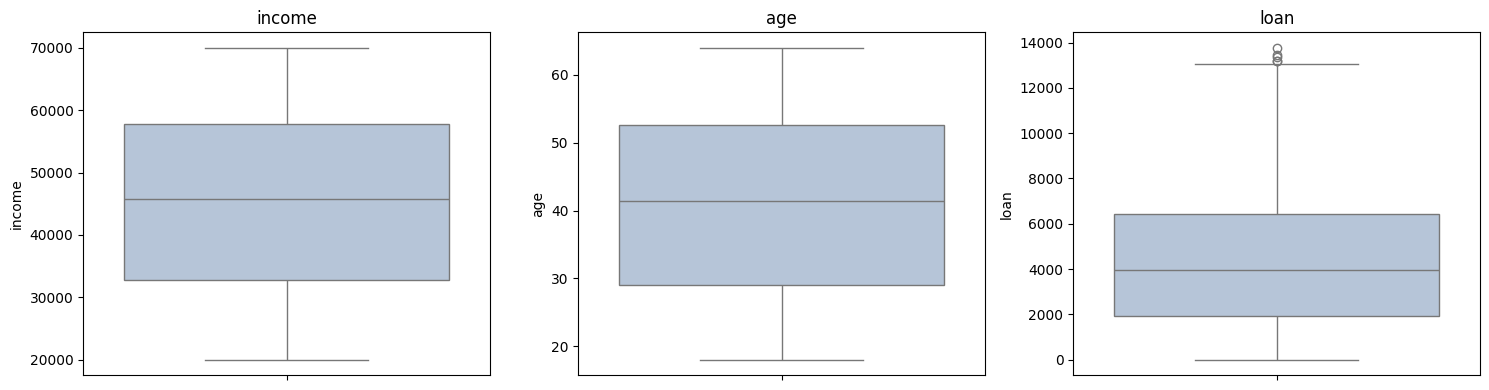

In [46]:
#Boxplots ( Points Beyond the Whiskers = IQR Outliers )
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df_clean[col], ax=ax, color='lightsteelblue')
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [47]:
#Multivariate Outliers ( Rows that are Strange Considering All the Attributes Together )
scaled = StandardScaler().fit_transform(df_clean[num_cols])
flags = pd.DataFrame({'IQR': np.logical_or.reduce([flag_iqr(df_clean[col]).values for col in num_cols]),
                      'Isolation Forest': IsolationForest(contamination=0.01, random_state=SEED).fit_predict(scaled) == -1,
                      'LOF': LocalOutlierFactor(n_neighbors=20, contamination=0.01).fit_predict(scaled) == -1})
print(flags.sum())

#Metrics ( Agreement Between the Methods: Jaccard Index, 1 = the Same Rows )
jaccard = lambda a, b: (a & b).sum() / max((a | b).sum(), 1)
print(pd.DataFrame({a: {b: jaccard(flags[a], flags[b]) for b in flags} for a in flags}).round(3))

IQR                  5
Isolation Forest    20
LOF                 20
dtype: int64
                    IQR  Isolation Forest    LOF
IQR               1.000             0.190  0.042
Isolation Forest  0.190             1.000  0.176
LOF               0.042             0.176  1.000


In [48]:
#Metrics ( Are the Outliers Informative? Default Rate of the Outliers vs the Other Rows )
for method in flags:
    print(f'{method:<18} outliers: {flags[method].sum():>4} | default rate outliers / others (%): {df_clean.loc[flags[method], "result"].mean() * 100:5.1f} / {df_clean.loc[~flags[method], "result"].mean() * 100:5.1f}')

IQR                outliers:    5 | default rate outliers / others (%):  40.0 /  14.1
Isolation Forest   outliers:   20 | default rate outliers / others (%):  45.0 /  13.8
LOF                outliers:   20 | default rate outliers / others (%):  15.0 /  14.1


In [49]:
#Option 01 - Remove the Rows ( IQR in Any Attribute )
df_test = df_clean[~flags['IQR']]
print(df_test.shape)

(1995, 5)


In [50]:
#Option 02 - Clip to the IQR Fences ( The Extreme Values Become the Limit )
def clip_iqr(s, k=1.5):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return s.clip(q1 - k * iqr, q3 + k * iqr)

df_test = df_clean.copy()
df_test['loan'] = clip_iqr(df_test['loan'])
print(df_test['loan'].describe().round(2))

count     2000.00
mean      4443.82
std       3043.81
min          1.38
25%       1939.71
50%       3974.72
75%       6432.41
max      13171.46
Name: loan, dtype: float64


In [51]:
#Option 03 - Clip to Percentiles ( Winsorization: 1% and 99% )
df_test = df_clean.copy()
df_test['loan'] = df_test['loan'].clip(df_clean['loan'].quantile(0.01), df_clean['loan'].quantile(0.99))
print(df_test['loan'].describe().round(2))

count     2000.00
mean      4438.33
std       3027.02
min         95.45
25%       1939.71
50%       3974.72
75%       6432.41
max      12177.15
Name: loan, dtype: float64


In [52]:
#Option 04 - Log Transformation ( Reduces the Distance of the Extreme Values )
df_test = df_clean.copy()
df_test['loan'] = np.log1p(df_test['loan'])
print(df_test['loan'].describe().round(2))

count    2000.00
mean        8.04
std         1.04
min         0.87
25%         7.57
50%         8.29
75%         8.77
max         9.53
Name: loan, dtype: float64


In [53]:
#Compare the Options ( Metrics of the Quality of Each Treatment for the Attribute loan )
options = {'Original': df_clean['loan'], 'Clip IQR fences': clip_iqr(df_clean['loan']),
           'Clip percentiles 1-99': df_clean['loan'].clip(df_clean['loan'].quantile(0.01), df_clean['loan'].quantile(0.99)),
           'Log transformation': np.log1p(df_clean['loan'])}
pd.DataFrame({name: {'values_changed_%': (s != df_clean['loan']).mean() * 100, 'IQR_outliers_left': int(flag_iqr(s).sum()),
                     'skewness': s.skew(), 'excess_kurtosis': s.kurt(), 'std': s.std(),
                     'spearman_with_result': s.corr(df_clean['result'], method='spearman')} for name, s in options.items()}).T.round(4)

,values_changed_%,IQR_outliers_left,skewness,excess_kurtosis,std,spearman_with_result
Original,0.00,5.0,0.6243,-0.3373,3045.4100,0.3695
Clip IQR fences,0.25,0.0,0.6212,-0.3495,3043.8054,0.3695
Clip percentiles 1-99,2.00,0.0,0.5952,-0.4417,3027.0198,0.3696
Log transformation,100.00,69.0,-1.5675,3.7960,1.0405,0.3695


### **06. Feature Engineering**

Create **new attributes** from the existing ones: ratios, logarithms, interactions, bins and categories. The credit data has only numeric attributes, so categorical attributes are created here to practice the next section: three **ordinal** ones ( bins with an order ) and one **nominal** ( `region`, random and synthetic: see the Enrichment notebook ).

In [54]:
#Create the Dataframe for the New Attributes
df_fe = df_clean.copy()

In [55]:
#Create Ratio and Logarithm Attributes
df_fe['loan_to_income'] = df_fe['loan'] / df_fe['income']
df_fe['log_loan'] = np.log1p(df_fe['loan'])
df_fe['log_income'] = np.log1p(df_fe['income'])
df_fe[['loan_to_income', 'log_loan', 'log_income']].describe().round(4)

,loan_to_income,log_loan,log_income
count,2000.0000,2000.0000,2000.0000
mean,0.0984,8.0401,10.6660
std,0.0576,1.0405,0.3447
min,0.0000,0.8661,9.9043
25%,0.0479,7.5708,10.3981
50%,0.0994,8.2880,10.7318
75%,0.1476,8.7693,10.9646
max,0.1999,9.5300,11.1562


In [56]:
#Create Polynomial and Interaction Attributes ( PolynomialFeatures )
poly = PolynomialFeatures(degree=2, include_bias=False)
poly_values = pd.DataFrame(poly.fit_transform(df_clean[num_cols]), columns=poly.get_feature_names_out(num_cols))
print(poly_values.columns.tolist())
df_fe['age_squared'] = poly_values['age^2'].values
df_fe['age_x_loan'] = poly_values['age loan'].values

['income', 'age', 'loan', 'income^2', 'income age', 'income loan', 'age^2', 'age loan', 'loan^2']


In [57]:
#Create Categorical Attributes from Numeric Ranges ( Ordinal: Bins with an Order )
age_order = ['18-30', '31-40', '41-50', '51+']
band_order = ['Low', 'Medium-Low', 'Medium-High', 'High']
df_fe['age_group'] = pd.cut(df_fe['age'], bins=[0, 30, 40, 50, np.inf], labels=age_order)      # Fixed edges
df_fe['income_band'] = pd.qcut(df_fe['income'], q=4, labels=band_order)                         # Quartiles
df_fe['loan_band'] = pd.qcut(df_fe['loan'], q=4, labels=band_order)

#Metrics ( Rows per Category and Default Rate: a Good Bin Separates the Classes )
for col in ['age_group', 'income_band', 'loan_band']:
    print(df_fe.groupby(col, observed=True)['result'].agg(rows='count', default_rate_pct=lambda s: s.mean() * 100).round(2), '\n')

           rows  default_rate_pct
age_group                        
18-30       541             38.45
31-40       403             18.61
41-50       441              0.00
51+         615              0.00 

             rows  default_rate_pct
income_band                        
Low           500              13.4
Medium-Low    500              14.6
Medium-High   500              15.0
High          500              13.6 

             rows  default_rate_pct
loan_band                          
Low           500               0.0
Medium-Low    500               6.2
Medium-High   500              17.0
High          500              33.4 



In [58]:
#The Same Bins with Scikit-Learn ( KBinsDiscretizer: Learns the Edges from the Train Data )
kbins = KBinsDiscretizer(n_bins=4, encode='ordinal', strategy='quantile')
loan_bins = kbins.fit_transform(df_fe[['loan']]).ravel()
print('Bin edges:', kbins.bin_edges_[0].round(1))
print('Same bins as pd.qcut:', (loan_bins == df_fe['loan_band'].cat.codes.values).mean() == 1.0)

Bin edges: [1.40000e+00 1.93970e+03 3.97470e+03 6.43240e+03 1.37661e+04]
Same bins as pd.qcut: True


In [59]:
#Create a Nominal Attribute ( No Order: Region ) and a Random Attribute to Test the Methods
regions = ['North', 'South', 'East', 'West', 'Central']
df_fe['region'] = np.random.default_rng(SEED).choice(regions, size=len(df_fe), p=[0.15, 0.25, 0.20, 0.25, 0.15])
df_fe['random_noise'] = np.random.default_rng(SEED + 1).normal(size=len(df_fe))      # Has no relation with the result: a sanity check
print(df_fe['region'].value_counts().to_dict())

{'South': 493, 'West': 492, 'East': 406, 'Central': 313, 'North': 296}


In [60]:
#Metrics ( Does the New Attribute Carry Information About the Result? Mutual Information and Spearman Correlation )
numeric_features = num_cols + ['loan_to_income', 'log_loan', 'log_income', 'age_squared', 'age_x_loan', 'random_noise']
pd.DataFrame({'mutual_information': mutual_info_classif(df_fe[numeric_features], df_fe['result'], random_state=SEED),
              'spearman_with_result': [df_fe[col].corr(df_fe['result'], method='spearman') for col in numeric_features]},
             index=numeric_features).sort_values('mutual_information', ascending=False).round(4)

,mutual_information,spearman_with_result
age_squared,0.1519,-0.4426
age,0.1518,-0.4426
loan_to_income,0.1474,0.4342
log_loan,0.0852,0.3695
loan,0.0849,0.3695
age_x_loan,0.0580,0.1175
log_income,0.0011,0.0024
income,0.0010,0.0024
random_noise,0.0000,0.0145


### **07. Fix Categorical Values**

Machine Learning models need numbers. The right encoding depends on the type of the attribute:

| Type | Example | Encoding |
|---|---|---|
| **Ordinal** ( has an order ) | `age_group`, `income_band` | Ordinal encoding with **the order defined by us** |
| **Nominal** ( no order ) | `region` | **Dummies** ( one-hot ) |
| Nominal with many categories | city, product | Frequency or target encoding |
| Classifier ( Y ) | Paid / Default | Label encoding |

**Attention!** Label encoding gives numbers by alphabetical order. For a nominal attribute the model will think that `West` ( 4 ) is "bigger" than `East` ( 1 ).

In [61]:
#Select the Categorical Attributes
cat_cols = ['age_group', 'income_band', 'loan_band', 'region']
df_cat = df_fe[cat_cols].astype(str)
print(df_cat.head(3))

  age_group  income_band loan_band   region
0       51+         High      High     West
1     41-50   Medium-Low      High     East
2       51+  Medium-High      High  Central


In [62]:
#Metrics ( Cardinality, Relation with the Result: Cramer's V and Mutual Information )
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(table, correction=False)[0]
    n = table.values.sum()
    r, k = table.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))                  # Bias correction
    r_corr, k_corr = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / min(k_corr - 1, r_corr - 1))

codes = pd.DataFrame({col: df_cat[col].astype('category').cat.codes for col in cat_cols})
pd.DataFrame({'cardinality': df_cat.nunique(),
              'cramers_v_with_result': [cramers_v(df_cat[col], df_fe['result']) for col in cat_cols],
              'mutual_information': mutual_info_classif(codes, df_fe['result'], discrete_features=True, random_state=SEED)}).round(4)

,cardinality,cramers_v_with_result,mutual_information
age_group,4,0.4695,0.1306
income_band,4,0.0000,0.0002
loan_band,4,0.3615,0.0764
region,5,0.0000,0.0005


In [63]:
#Option 01 - Label Encoding ( Loop for All the Categorical Attributes )
df_label = df_fe.copy()
labelencoder = LabelEncoder()
for col in cat_cols:
    df_label[col] = labelencoder.fit_transform(df_fe[col].astype(str))
print(df_label[cat_cols].head())

#Attention! Look at the order: the alphabetical order is NOT the order of the income
labelencoder.fit(df_cat['income_band'])
print(dict(zip(labelencoder.classes_, labelencoder.transform(labelencoder.classes_))))

   age_group  income_band  loan_band  region
0          3            0          0       4
1          2            3          0       1
2          3            2          0       0
3          2            3          2       4
4          0            0          0       2
{'High': np.int64(0), 'Low': np.int64(1), 'Medium-High': np.int64(2), 'Medium-Low': np.int64(3)}


In [64]:
#Option 02 [Recommended for Ordinal Attributes] - Ordinal Encoding with the Order Defined by Us
ordinal_cols = ['age_group', 'income_band', 'loan_band']
ordinalencoder = OrdinalEncoder(categories=[age_order, band_order, band_order])
df_ordinal = df_fe.copy()
df_ordinal[ordinal_cols] = ordinalencoder.fit_transform(df_cat[ordinal_cols])
print(df_ordinal[ordinal_cols].head())
print(dict(zip(band_order, range(4))))

#Metrics ( The Encoded Value Follows the Order of the Category: Spearman with the Numeric Attribute )
print('Spearman income_band x income:', round(df_ordinal['income_band'].corr(df_fe['income'], method='spearman'), 3))

   age_group  income_band  loan_band
0        3.0          3.0        3.0
1        2.0          1.0        3.0
2        3.0          2.0        3.0
3        2.0          1.0        2.0
4        0.0          3.0        3.0
{'Low': 0, 'Medium-Low': 1, 'Medium-High': 2, 'High': 3}
Spearman income_band x income: 0.968


In [65]:
#Option 03 - Replace with a Dictionary ( Manual Mapping )
mapping = {label: number for number, label in enumerate(age_order)}
print(mapping)
df_fe['age_group'].astype(str).map(mapping).head()

{'18-30': 0, '31-40': 1, '41-50': 2, '51+': 3}


,age_group
0,3
1,2
2,3
3,2
4,0


In [66]:
#Option 04 - Dummies with Pandas ( get_dummies )
dummies = pd.get_dummies(df_fe['region'], prefix='region', dtype=int)
print(dummies.head())

#Metrics ( Dummy Variable Trap: the Columns Sum 1, so One Column is Redundant. Rank < Columns + Intercept )
with_intercept = np.c_[np.ones(len(dummies)), dummies.values]
print('\nColumns + intercept:', with_intercept.shape[1], '| Matrix rank:', np.linalg.matrix_rank(with_intercept), '( rank lower than columns = redundant column )')

   region_Central  region_East  region_North  region_South  region_West
0               0            0             0             0            1
1               0            1             0             0            0
2               1            0             0             0            0
3               0            0             0             0            1
4               0            0             1             0            0

Columns + intercept: 6 | Matrix rank: 5 ( rank lower than columns = redundant column )


In [67]:
#Option 05 - Dummies Without the Redundant Column ( drop_first=True )
dummies_drop = pd.get_dummies(df_fe['region'], prefix='region', drop_first=True, dtype=int)
with_intercept = np.c_[np.ones(len(dummies_drop)), dummies_drop.values]
print(dummies_drop.columns.tolist())
print('Columns + intercept:', with_intercept.shape[1], '| Matrix rank:', np.linalg.matrix_rank(with_intercept))

['region_East', 'region_North', 'region_South', 'region_West']
Columns + intercept: 5 | Matrix rank: 5


In [68]:
#Option 06 - OneHotEncoder with ColumnTransformer ( Dummies Variables )
onehotencoder = ColumnTransformer(transformers=[('OneHot', OneHotEncoder(sparse_output=False, drop='first'), cat_cols)], remainder='passthrough')
X_encoded = onehotencoder.fit_transform(pd.concat([df_cat, df_fe[num_cols]], axis=1))

#After fix the Dummies Values, we need to convert the Array to DataFrame
X_encoded = pd.DataFrame(data=X_encoded, columns=onehotencoder.get_feature_names_out())
print(X_encoded.shape)
X_encoded.head(3)

(2000, 16)


,OneHot__age_group_31-40,OneHot__age_group_41-50,OneHot__age_group_51+,OneHot__income_band_Low,OneHot__income_band_Medium-High,OneHot__income_band_Medium-Low,OneHot__loan_band_Low,OneHot__loan_band_Medium-High,OneHot__loan_band_Medium-Low,OneHot__region_East,OneHot__region_North,OneHot__region_South,OneHot__region_West,remainder__income,remainder__age,remainder__loan
0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,66155.925095,59.017015,8106.532131
1,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,34415.153966,48.117153,6564.745018
2,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,57317.170063,63.108049,8020.953296


In [69]:
#Option 07 - Frequency Encoding ( Each Category Becomes its Share in the Data )
df_freq = pd.DataFrame({col: df_cat[col].map(df_cat[col].value_counts(normalize=True)) for col in cat_cols})
df_freq.head(3)

,age_group,income_band,loan_band,region
0,0.3075,0.25,0.25,0.2460
1,0.2205,0.25,0.25,0.2030
2,0.3075,0.25,0.25,0.1565


In [70]:
#Option 08 - Target Encoding ( Each Category Becomes the Mean of the Result: Cross-Fitting Avoids Leakage )
#Attention! Fit it ONLY with the train data ( use it inside a Pipeline ). Fitting it with all the data lets the target leak into the attribute
target_encoder = TargetEncoder(target_type='binary', cv=5, random_state=SEED)
df_target = pd.DataFrame(target_encoder.fit_transform(df_cat, df_fe['result']), columns=cat_cols)
print(df_target.head(3))
print(dict(zip(target_encoder.categories_[3], target_encoder.encodings_[3].round(4))))

   age_group  income_band  loan_band    region
0        0.0     0.129799   0.332487  0.152034
1        0.0     0.143559   0.325792  0.153313
2        0.0     0.148865   0.338440  0.127464
{'Central': np.float64(0.1342), 'East': np.float64(0.1576), 'North': np.float64(0.152), 'South': np.float64(0.1278), 'West': np.float64(0.1402)}


In [71]:
#Encode the Classifier ( Text Labels to Numbers )
#Attention! LabelEncoder sorts the labels alphabetically: Default = 0 and Paid = 1, the opposite of the original result
labels = df_fe['result'].map({0: 'Paid', 1: 'Default'})
target_label_encoder = LabelEncoder().fit(labels)
print(dict(zip(target_label_encoder.classes_, target_label_encoder.transform(target_label_encoder.classes_))))
print('Inverse transform of [0, 1]:', target_label_encoder.inverse_transform([0, 1]))

{'Default': np.int64(0), 'Paid': np.int64(1)}
Inverse transform of [0, 1]: ['Default' 'Paid']


In [72]:
#Compare the Encodings ( Using ONLY the Categorical Attributes to Predict the Result: Cross-Validated ROC AUC )
encoders = {'Label ( alphabetical )': OrdinalEncoder(),
            'Ordinal ( order defined ) + One-Hot for the nominal': ColumnTransformer([('ord', OrdinalEncoder(categories=[age_order, band_order, band_order]), ordinal_cols),
                                                                                       ('nom', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), ['region'])]),
            'One-Hot': OneHotEncoder(sparse_output=False, handle_unknown='ignore'),
            'One-Hot ( drop first )': OneHotEncoder(sparse_output=False, drop='first', handle_unknown='ignore'),
            'Target Encoding': TargetEncoder(target_type='binary', cv=5, random_state=SEED)}
rows = {}
for name, encoder in encoders.items():
    rows[name] = {'columns_created': clone(encoder).fit_transform(df_cat, df_fe['result']).shape[1],
                  'logistic_regression_AUC': cross_val_score(make_pipeline(clone(encoder), StandardScaler(), LogisticRegression(max_iter=1000)), df_cat, df_fe['result'], cv=cv, scoring='roc_auc').mean(),
                  'random_forest_AUC': cross_val_score(make_pipeline(clone(encoder), RandomForestClassifier(n_estimators=100, min_samples_leaf=5, random_state=SEED, n_jobs=-1)), df_cat, df_fe['result'], cv=cv, scoring='roc_auc').mean()}
pd.DataFrame(rows).T.round(4)

,columns_created,logistic_regression_AUC,random_forest_AUC
Label ( alphabetical ),4.0,0.8967,0.9717
Ordinal ( order defined ) + One-Hot for the nominal,8.0,0.9692,0.9699
One-Hot,17.0,0.9735,0.9727
One-Hot ( drop first ),13.0,0.9734,0.9697
Target Encoding,4.0,0.9390,0.9587


### **08. Scaling**

Standardization and normalization are data scaling techniques used to transform the values of numeric attributes to a similar range. This is crucial for algorithms that are sensitive to the scale, as those based on distances ( K-Nearest Neighbors, SVM, K-Means ) and those trained with gradient descent ( Logistic Regression, Neural Networks ). Decision trees do **not** need scaling.

### Standardization ( Z-score )

Mean 0 and standard deviation 1. Works well for data close to a normal distribution.

## $x' = \frac{x - \mu}{\sigma}$

### Normalization ( Min-Max )

Values between 0 and 1. Useful when we need a bounded range, but it is sensitive to outliers.

## $x' = \frac{x - x_{min}}{x_{max} - x_{min}}$

**Attention!** Learn the scaler ( `fit` ) only with the **train** data and apply it ( `transform` ) to train and test. Fitting with all the data is a leakage.

In [73]:
#Show the Scale of the Attributes ( Very Different: income x age x loan )
df_clean[num_cols].describe().loc[['mean', 'std', 'min', 'max']].round(2)

,income,age,loan
mean,45331.60,40.93,4444.37
std,14326.33,13.25,3045.41
min,20014.49,18.06,1.38
max,69995.69,63.97,13766.05


In [74]:
#Split the DataFrame (X) in Data and Classifier (Y)
X = df_clean[num_cols].values
Y = df_clean['result'].values

In [75]:
#Example of Standardization with Scaler
scaler = StandardScaler()
X_standard = scaler.fit_transform(X)
print(X_standard[:5])

#Metrics ( Mean 0 and Standard Deviation 1 )
print(pd.DataFrame(X_standard, columns=num_cols).agg(['mean', 'std']).round(4))

[[ 1.45393393  1.36527462  1.20281942]
 [-0.76217555  0.54255534  0.69642695]
 [ 0.83682073  1.67406504  1.17471147]
 [-0.18307006  0.364032    0.54497999]
 [ 1.50956319 -1.68657546  1.4207648 ]]
      income     age    loan
mean  0.0000  0.0000  0.0000
std   1.0003  1.0003  1.0003


In [76]:
#Renew the Data
X = df_clean[num_cols].values

In [77]:
#Example of Normalization with Scaler
scaler = MinMaxScaler(feature_range=(0, 1))
X_minmax = scaler.fit_transform(X)
print(X_minmax[:5])

#Metrics ( Minimum 0 and Maximum 1 )
print(pd.DataFrame(X_minmax, columns=num_cols).agg(['min', 'max']).round(4))

[[0.9231759  0.89209175 0.58883739]
 [0.28812165 0.65470788 0.47682695]
 [0.74633429 0.9811888  0.58262011]
 [0.45407166 0.60319752 0.44332796]
 [0.93911717 0.0115241  0.63704537]]
     income  age  loan
min     0.0  0.0   0.0
max     1.0  1.0   1.0


In [78]:
#Fit Only with the Train Data ( Correct Way )
X_train, X_test, Y_train, Y_test = train_test_split(df_clean[num_cols], df_clean['result'], test_size=0.25, random_state=SEED, stratify=df_clean['result'])
scaler = StandardScaler().fit(X_train)                  # Learns the mean and the standard deviation ONLY with the train data
X_train_scaled, X_test_scaled = scaler.transform(X_train), scaler.transform(X_test)

#Metrics ( Train Has Mean 0 and Std 1 by Construction. The Test Does Not, and That is Expected: it is New Data )
print(pd.DataFrame({'train_mean': X_train_scaled.mean(axis=0), 'train_std': X_train_scaled.std(axis=0),
                    'test_mean': X_test_scaled.mean(axis=0), 'test_std': X_test_scaled.std(axis=0)}, index=num_cols).round(4))

        train_mean  train_std  test_mean  test_std
income         0.0        1.0    -0.0268    1.0280
age            0.0        1.0     0.0144    1.0162
loan           0.0        1.0     0.0085    0.9621


In [79]:
#Other Scalers ( Each One Solves a Different Problem )
scalers = {'Standard ( mean 0, std 1 )': StandardScaler(), 'MinMax ( 0 to 1 )': MinMaxScaler(),
           'Robust ( median and IQR )': RobustScaler(), 'MaxAbs ( -1 to 1 )': MaxAbsScaler(),
           'Power ( Yeo-Johnson )': PowerTransformer(method='yeo-johnson'),
           'Quantile ( normal output )': QuantileTransformer(n_quantiles=200, output_distribution='normal', random_state=SEED),
           'Log1p': FunctionTransformer(np.log1p, inverse_func=np.expm1),
           'Normalizer ( each ROW with norm 1 )': Normalizer()}
X_num = df_clean[num_cols]

#Metrics ( Statistics of the Attributes After Each Scaler )
rows = {}
for name, scaler in scalers.items():
    scaled = pd.DataFrame(np.asarray(clone(scaler).fit_transform(X_num)), columns=num_cols)
    rows[name] = {'mean_of_means': scaled.mean().mean(), 'mean_of_std': scaled.std().mean(), 'min': scaled.min().min(), 'max': scaled.max().max(), 'max_abs_skewness': scaled.skew().abs().max()}
pd.DataFrame(rows).T.round(4)

,mean_of_means,mean_of_std,min,max,max_abs_skewness
"Standard ( mean 0, std 1 )",0.0000,1.0003,-1.7676,3.0617,0.6243
MinMax ( 0 to 1 ),0.4425,0.2655,0.0000,1.0000,0.6243
Robust ( median and IQR ),0.0223,0.6051,-1.0312,2.1794,0.6243
MaxAbs ( -1 to 1 ),0.5368,0.2110,0.0001,1.0000,0.6243
Power ( Yeo-Johnson ),-0.0000,1.0003,-2.5071,2.2413,0.1377
Quantile ( normal output ),0.0000,1.0106,-5.1993,5.1993,0.0210
Log1p,7.4622,0.5760,0.8661,11.1562,1.5675
Normalizer ( each ROW with norm 1 ),0.3640,0.0210,0.0000,1.0000,1.0537


In [80]:
#Metrics ( Reversibility: Can We Return to the Original Values? Maximum Error After inverse_transform )
for name, scaler in scalers.items():
    if name.startswith('Normalizer'):
        print(f'{name:<38} no inverse_transform ( the norm of each row is lost )')
        continue
    fitted = clone(scaler).fit(X_num)
    error = np.abs(np.asarray(fitted.inverse_transform(fitted.transform(X_num))) - X_num.values).max()
    print(f'{name:<38} maximum error: {error:.2e}')

Standard ( mean 0, std 1 )             maximum error: 3.64e-12
MinMax ( 0 to 1 )                      maximum error: 7.28e-12
Robust ( median and IQR )              maximum error: 3.64e-12
MaxAbs ( -1 to 1 )                     maximum error: 7.28e-12
Power ( Yeo-Johnson )                  maximum error: 7.28e-11
Quantile ( normal output )             maximum error: 1.46e-11
Log1p                                  maximum error: 5.82e-11
Normalizer ( each ROW with norm 1 )    no inverse_transform ( the norm of each row is lost )


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PowerTransformer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but QuantileTransformer was fitted with feature names
  warnings.warn(


In [81]:
#Metrics ( Shape of the Attribute loan After Each Scaler: Skewness, Excess Kurtosis and Normality Test )
rows = {}
for name, scaler in scalers.items():
    if name.startswith('Normalizer'):
        continue
    values = np.asarray(clone(scaler).fit_transform(X_num[['loan']])).ravel()
    rows[name] = {'skewness': stats.skew(values), 'excess_kurtosis': stats.kurtosis(values), 'normaltest_pvalue': stats.normaltest(values).pvalue}
pd.DataFrame(rows).T.round(4)

,skewness,excess_kurtosis,normaltest_pvalue
"Standard ( mean 0, std 1 )",0.6238,-0.3395,0.0000
MinMax ( 0 to 1 ),0.6238,-0.3395,0.0000
Robust ( median and IQR ),0.6238,-0.3395,0.0000
MaxAbs ( -1 to 1 ),0.6238,-0.3395,0.0000
Power ( Yeo-Johnson ),-0.1376,-0.6760,0.0000
Quantile ( normal output ),-0.0108,0.4545,0.0021
Log1p,-1.5663,3.7835,0.0000


In [82]:
#Metrics ( Sensitivity to Outliers: Add One Extreme Loan and See How the Scaled Attribute Changes )
loan_outlier = df_clean[['loan']].copy()
loan_outlier.iloc[0, 0] = df_clean['loan'].max() * 10
for name, scaler in {'MinMax': MinMaxScaler(), 'Standard': StandardScaler(), 'Robust': RobustScaler()}.items():
    without = scaler.fit_transform(df_clean[['loan']]).std()
    with_outlier = scaler.fit_transform(loan_outlier).std()
    print(f'{name:<9} std of the scaled attribute without / with the outlier: {without:.3f} / {with_outlier:.3f}  ( change: {(with_outlier / without - 1) * 100:6.1f}% )')

MinMax    std of the scaled attribute without / with the outlier: 0.221 / 0.031  ( change:  -86.0% )
Standard  std of the scaled attribute without / with the outlier: 1.000 / 1.000  ( change:   -0.0% )
Robust    std of the scaled attribute without / with the outlier: 0.678 / 0.948  ( change:   39.9% )


In [83]:
#Metrics ( Does Scaling Improve the Models? Cross-Validated ROC AUC, the Scaler Inside the Pipeline )
models = {'KNN': KNeighborsClassifier(n_neighbors=15), 'SVM ( RBF )': SVC(), 'Logistic Regression': LogisticRegression(max_iter=1000),
          'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=SEED)}
rows = {}
for model_name, model in models.items():
    row = {'No scaling': cross_val_score(model, X_num, df_clean['result'], cv=cv, scoring='roc_auc').mean()}
    for scaler_name, scaler in scalers.items():
        row[scaler_name] = cross_val_score(make_pipeline(clone(scaler), model), X_num, df_clean['result'], cv=cv, scoring='roc_auc').mean()
    rows[model_name] = row
scaling_benchmark = pd.DataFrame(rows).T
scaling_benchmark.round(4)

,No scaling,"Standard ( mean 0, std 1 )",MinMax ( 0 to 1 ),Robust ( median and IQR ),MaxAbs ( -1 to 1 ),Power ( Yeo-Johnson ),Quantile ( normal output ),Log1p,Normalizer ( each ROW with norm 1 )
KNN,0.8514,0.9978,0.9973,0.9976,0.9977,0.9974,0.9956,0.9979,0.8919
SVM ( RBF ),0.8448,0.9977,0.9971,0.9980,0.9968,0.9975,0.9956,0.9822,0.8593
Logistic Regression,0.9837,0.9838,0.9815,0.9836,0.9813,0.9863,0.9678,0.9848,0.8597
Decision Tree,0.9677,0.9677,0.9677,0.9677,0.9677,0.9677,0.9677,0.9677,0.9499


In [84]:
#Metrics ( Improvement of the Best Scaler vs No Scaling, per Model: the Tree is Expected to Change Nothing )
# The Normalizer works on rows ( not on columns ), so it is not compared here
column_scalers = scaling_benchmark.drop(columns=['No scaling'] + [c for c in scaling_benchmark.columns if c.startswith('Normalizer')])
improvement = column_scalers.max(axis=1) - scaling_benchmark['No scaling']
pd.DataFrame({'best_scaler': column_scalers.idxmax(axis=1), 'AUC_gain': improvement}).round(4)

,best_scaler,AUC_gain
KNN,Log1p,0.1465
SVM ( RBF ),Robust ( median and IQR ),0.1531
Logistic Regression,Power ( Yeo-Johnson ),0.0026
Decision Tree,Quantile ( normal output ),0.0000


| Scaler | Use when | Attention |
|---|---|---|
| `StandardScaler` | Default choice for SVM, KNN, regression, PCA, neural networks | Sensitive to outliers |
| `MinMaxScaler` | You need a fixed range ( 0 to 1 ), neural networks, images | Very sensitive to outliers |
| `RobustScaler` | The data has outliers | Does not bound the values |
| `MaxAbsScaler` | Sparse data ( keeps the zeros ) | Sensitive to outliers |
| `PowerTransformer` / `QuantileTransformer` | Skewed data that should look normal | Changes the shape of the distribution |
| `Log1p` | Positive and right skewed attributes ( income, loan ) | Does not accept values below -1 |
| `Normalizer` | Each **row** must have the same length ( text, cosine similarity ) | Not a column scaler |

### **09. Imbalanced Classes**

Only about 14% of the clients default. A model can ignore the rare class and still have a high accuracy ( always answering "no default" is right 86% of the time ). The techniques below help the model to learn the rare class, and **must be applied only to the train data**.

| Technique | Idea | Attention |
|---|---|---|
| Class weights | The rare class has a bigger weight in the loss | Does not change the data |
| Random oversampling | Repeats rows of the rare class | Can overfit ( exact copies ) |
| Random undersampling | Removes rows of the common class | Loses information |
| SMOTE-like | Creates new rows between neighbors of the rare class | Can create unrealistic rows |
| Threshold moving | Changes the cut of the probability ( not 0.5 ) | Choose it with the train data, never with the test |

In [85]:
#Show the Distribution of the Classifier ( Imbalance Ratio )
counts = df_clean['result'].value_counts()
print(counts.to_dict())
print('Positive rate (%):', round(df_clean['result'].mean() * 100, 2), '| Imbalance ratio ( majority : minority ):', round(counts.max() / counts.min(), 1), ': 1')
print('Accuracy of a model that always answers 0 (%):', round(counts.max() / len(df_clean) * 100, 2))

{0: 1717, 1: 283}
Positive rate (%): 14.15 | Imbalance ratio ( majority : minority ): 6.1 : 1
Accuracy of a model that always answers 0 (%): 85.85


In [86]:
#Split the Data First ( Resample Only the Train Data )
X_train, X_test, y_train, y_test = train_test_split(df_clean[num_cols], df_clean['result'], test_size=0.25, random_state=SEED, stratify=df_clean['result'])
print(X_train.shape, X_test.shape, '| Positive rate train / test (%):', round(y_train.mean() * 100, 2), '/', round(y_test.mean() * 100, 2))

(1500, 3) (500, 3) | Positive rate train / test (%): 14.13 / 14.2


In [87]:
#Define the Classification Metrics and the Evaluation Function
def classification_metrics(y_true, y_pred, y_proba):
    return {'accuracy': accuracy_score(y_true, y_pred), 'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
            'precision': precision_score(y_true, y_pred, zero_division=0), 'recall': recall_score(y_true, y_pred),
            'f1': f1_score(y_true, y_pred), 'roc_auc': roc_auc_score(y_true, y_proba),
            'pr_auc': average_precision_score(y_true, y_proba), 'mcc': matthews_corrcoef(y_true, y_pred)}

def make_model(**kwargs):
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, **kwargs))

def evaluate_model(model, X_tr, y_tr, X_te, y_te, threshold=0.5):
    model.fit(X_tr, y_tr)
    proba = model.predict_proba(X_te)[:, 1]
    return classification_metrics(y_te, (proba >= threshold).astype(int), proba)

results = {}

In [88]:
#Baseline ( No Treatment )
results['Baseline'] = evaluate_model(make_model(), X_train, y_train, X_test, y_test)
pd.Series(results['Baseline']).round(4)

,0
accuracy,0.9300
balanced_accuracy,0.8417
precision,0.7727
recall,0.7183
f1,0.7445
roc_auc,0.9798
pr_auc,0.8865
mcc,0.7047


In [89]:
#Option 01 - Class Weights ( The Model Pays More Attention to the Rare Class )
results['Class weights'] = evaluate_model(make_model(class_weight='balanced'), X_train, y_train, X_test, y_test)

In [90]:
#Option 02 - Random Oversampling ( Repeat Rows of the Rare Class Until Both Classes Have the Same Size )
minority_up = resample(X_train[y_train == 1], replace=True, n_samples=int((y_train == 0).sum()), random_state=SEED)
X_over = pd.concat([X_train[y_train == 0], minority_up])
y_over = np.r_[np.zeros((y_train == 0).sum()), np.ones(len(minority_up))]
print('Rows after:', len(X_over), '| Positive rate (%):', round(y_over.mean() * 100, 2))
results['Random oversampling'] = evaluate_model(make_model(), X_over, y_over, X_test, y_test)

Rows after: 2576 | Positive rate (%): 50.0


In [91]:
#Option 03 - Random Undersampling ( Remove Rows of the Common Class Until Both Classes Have the Same Size )
majority_down = resample(X_train[y_train == 0], replace=False, n_samples=int((y_train == 1).sum()), random_state=SEED)
X_under = pd.concat([majority_down, X_train[y_train == 1]])
y_under = np.r_[np.zeros(len(majority_down)), np.ones((y_train == 1).sum())]
print('Rows after:', len(X_under), '| Positive rate (%):', round(y_under.mean() * 100, 2))
results['Random undersampling'] = evaluate_model(make_model(), X_under, y_under, X_test, y_test)

Rows after: 424 | Positive rate (%): 50.0


In [92]:
#Option 04 - SMOTE-like ( New Rows Between a Row of the Rare Class and One of its Nearest Neighbors )
# With the library imbalanced-learn: from imblearn.over_sampling import SMOTE / X_smote, y_smote = SMOTE(random_state=SEED).fit_resample(X_train, y_train)
def smote_interpolate(points, n_new, k=5, seed=SEED):
    rng = np.random.default_rng(seed)
    neighbors = NearestNeighbors(n_neighbors=k + 1).fit(points).kneighbors(points, return_distance=False)[:, 1:]
    base = rng.integers(0, len(points), n_new)
    chosen = neighbors[base, rng.integers(0, k, n_new)]
    return points[base] + rng.uniform(0, 1, (n_new, 1)) * (points[chosen] - points[base])

scaler = StandardScaler().fit(X_train)                              # Neighbors need the attributes in the same scale
minority_points = scaler.transform(X_train[y_train == 1])
n_new = int((y_train == 0).sum() - len(minority_points))
new_rows = scaler.inverse_transform(smote_interpolate(minority_points, n_new))
X_smote = np.vstack([X_train.values, new_rows])
y_smote = np.r_[y_train.values, np.ones(n_new)]
print('Rows after:', len(X_smote), '| Positive rate (%):', round(y_smote.mean() * 100, 2))
results['SMOTE-like'] = evaluate_model(make_model(), X_smote, y_smote, X_test, y_test)

Rows after: 2576 | Positive rate (%): 50.0


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [93]:
#Option 05 - Threshold Moving ( Choose the Cut that Maximizes the F1 with the TRAIN Data )
proba_train = cross_val_predict(make_model(), X_train, y_train, cv=cv, method='predict_proba')[:, 1]
thresholds = np.linspace(0.05, 0.95, 91)
f1_by_threshold = [f1_score(y_train, proba_train >= t) for t in thresholds]
best_threshold = thresholds[int(np.argmax(f1_by_threshold))]
print('Best threshold:', round(best_threshold, 2), '| F1 in the train ( cross-validated ):', round(max(f1_by_threshold), 4))
results[f'Threshold moving ( {best_threshold:.2f} )'] = evaluate_model(make_model(), X_train, y_train, X_test, y_test, threshold=best_threshold)

Best threshold: 0.54 | F1 in the train ( cross-validated ): 0.8312


In [94]:
#Compare the Techniques ( Accuracy Alone Hides the Problem: Look at Recall, F1, PR AUC and MCC )
pd.DataFrame(results).T.round(4)

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc,mcc
Baseline,0.930,0.8417,0.7727,0.7183,0.7445,0.9798,0.8865,0.7047
Class weights,0.934,0.9380,0.6979,0.9437,0.8024,0.9802,0.8891,0.7764
Random oversampling,0.936,0.9451,0.7010,0.9577,0.8095,0.9801,0.8888,0.7857
Random undersampling,0.926,0.9392,0.6667,0.9577,0.7861,0.9778,0.8779,0.7609
SMOTE-like,0.938,0.9404,0.7128,0.9437,0.8121,0.9803,0.8895,0.7868
Threshold moving ( 0.54 ),0.926,0.8217,0.7742,0.6761,0.7218,0.9798,0.8865,0.6814


In [95]:
#Confusion Matrices of the Baseline and of the Class Weights ( Rows = Real, Columns = Predicted )
for name, params in [('Baseline', {}), ('Class weights', {'class_weight': 'balanced'})]:
    model = make_model(**params).fit(X_train, y_train)
    print(name, '\n', pd.DataFrame(confusion_matrix(y_test, model.predict(X_test)), index=['real 0', 'real 1'], columns=['pred 0', 'pred 1']), '\n')

Baseline 
         pred 0  pred 1
real 0     414      15
real 1      20      51 

Class weights 
         pred 0  pred 1
real 0     400      29
real 1       4      67 



### **10. Feature Selection and Multicollinearity**

More attributes are not always better: **redundant** attributes ( multicollinearity ) make the model unstable and **useless** attributes add noise. A trick used here: a random attribute ( `random_noise` ) is included on purpose. Any attribute that is not better than the noise should be questioned.

In [96]:
#Select the Candidate Attributes ( Original + Engineered + the Random Attribute )
sel_cols = ['income', 'age', 'loan', 'loan_to_income', 'log_loan', 'age_squared', 'age_x_loan', 'random_noise']
X_sel, y_sel = df_fe[sel_cols], df_fe['result']

In [97]:
#Metrics ( Variance of the Scaled Attributes: an Attribute with Variance Close to Zero is Almost Constant )
scaled_sel = pd.DataFrame(MinMaxScaler().fit_transform(X_sel), columns=sel_cols)
variances = scaled_sel.var()
selector = VarianceThreshold(threshold=0.01).fit(scaled_sel)
print(variances.round(4).to_dict())
print('Removed by VarianceThreshold ( 0.01 ):', [c for c, keep in zip(sel_cols, selector.get_support()) if not keep])

{'income': 0.0822, 'age': 0.0833, 'loan': 0.049, 'loan_to_income': 0.0831, 'log_loan': 0.0144, 'age_squared': 0.0842, 'age_x_loan': 0.0305, 'random_noise': 0.0222}
Removed by VarianceThreshold ( 0.01 ): []


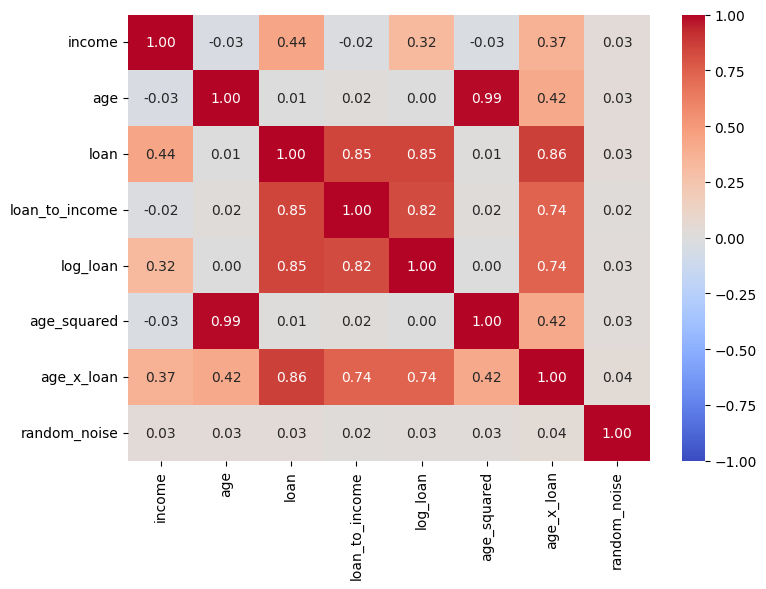

[('age', 'age_squared', np.float64(0.99)), ('loan', 'loan_to_income', np.float64(0.847)), ('loan', 'log_loan', np.float64(0.85)), ('loan', 'age_x_loan', np.float64(0.864)), ('loan_to_income', 'log_loan', np.float64(0.824))]


In [98]:
#Correlation Between the Attributes ( Pearson )
plt.figure(figsize=(8, 6))
sns.heatmap(X_sel.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.tight_layout()
plt.show()

#Metrics ( Pairs with Absolute Correlation Above 0.8: Candidates to Remove One of Them )
corr = X_sel.corr().abs()
pairs = [(a, b, round(corr.loc[a, b], 3)) for i, a in enumerate(sel_cols) for b in sel_cols[i + 1:] if corr.loc[a, b] > 0.8]
print(pairs)

In [99]:
#Variance Inflation Factor ( VIF ): How Much Each Attribute is Explained by the Others
def vif_table(data):
    rows = {}
    for col in data.columns:
        others = data.drop(columns=col)
        r2 = LinearRegression().fit(others, data[col]).score(others, data[col])
        rows[col] = 1 / (1 - r2) if r2 < 1 else np.inf
    return pd.Series(rows, name='VIF')

#Metrics ( VIF > 5 or 10 = Strong Multicollinearity )
vif_table(X_sel).round(2).sort_values(ascending=False)

,VIF
age,52.19
age_squared,49.77
loan,22.03
loan_to_income,14.52
age_x_loan,12.21
log_loan,4.74
income,4.46
random_noise,1.00


In [100]:
#Metrics ( Univariate Relation with the Result: ANOVA F-test and Mutual Information )
f_values, p_values = f_classif(X_sel, y_sel)
mutual_info = mutual_info_classif(X_sel, y_sel, random_state=SEED)
univariate = pd.DataFrame({'F_statistic': f_values, 'p_value': p_values, 'mutual_information': mutual_info}, index=sel_cols).sort_values('mutual_information', ascending=False)
univariate.round(4)

,F_statistic,p_value,mutual_information
age_squared,428.7048,0.0000,0.1519
age,493.8433,0.0000,0.1518
loan_to_income,461.7283,0.0000,0.1474
log_loan,205.8705,0.0000,0.0852
loan,331.3482,0.0000,0.0849
age_x_loan,1.2762,0.2587,0.0580
income,0.0104,0.9187,0.0010
random_noise,0.1586,0.6905,0.0000


In [101]:
#Rule: Keep the Attributes with More Information than the Random Attribute
noise_level = univariate.loc['random_noise', 'mutual_information']
selected = [col for col in univariate.index if univariate.loc[col, 'mutual_information'] > noise_level and col != 'random_noise']
print('Mutual information of the random attribute:', round(noise_level, 4))
print('Selected attributes:', selected)

Mutual information of the random attribute: 0.0
Selected attributes: ['age_squared', 'age', 'loan_to_income', 'log_loan', 'loan', 'age_x_loan', 'income']


In [102]:
#L1 Regularization ( Logistic Regression that Sets the Coefficient of Useless Attributes to Zero )
l1_model = make_pipeline(StandardScaler(), LogisticRegression(penalty='l1', solver='liblinear', C=0.05)).fit(X_sel, y_sel)
pd.Series(l1_model[-1].coef_[0], index=sel_cols, name='L1 coefficient').round(4)

,L1 coefficient
income,0.0000
age,-2.0832
loan,0.0000
loan_to_income,2.1322
log_loan,0.0000
age_squared,-0.1595
age_x_loan,0.0000
random_noise,0.0000


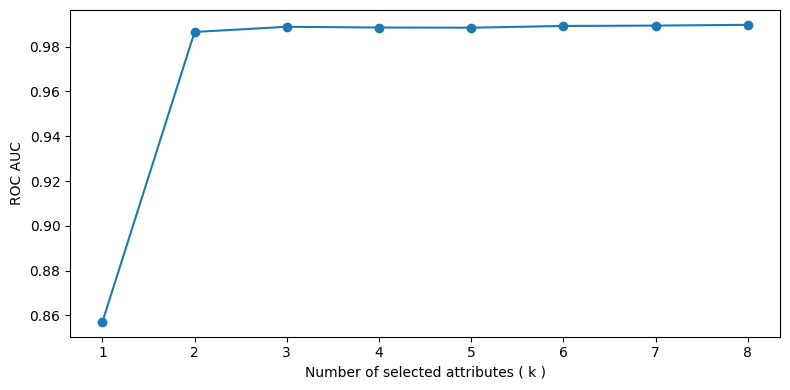

Best k: 8 | AUC: 0.9897 | AUC with all the attributes: 0.9897


In [103]:
#Metrics ( Performance with the k Best Attributes: Is Using Everything Better? Cross-Validated ROC AUC )
rows = {}
for k in range(1, len(sel_cols) + 1):
    model = make_pipeline(StandardScaler(), SelectKBest(f_classif, k=k), LogisticRegression(max_iter=1000))
    rows[k] = {'AUC': cross_val_score(model, X_sel, y_sel, cv=cv, scoring='roc_auc').mean()}
k_curve = pd.DataFrame(rows).T

plt.figure(figsize=(8, 4))
plt.plot(k_curve.index, k_curve['AUC'], 'o-')
plt.xlabel('Number of selected attributes ( k )')
plt.ylabel('ROC AUC')
plt.tight_layout()
plt.show()
print('Best k:', k_curve['AUC'].idxmax(), '| AUC:', round(k_curve['AUC'].max(), 4), '| AUC with all the attributes:', round(k_curve.loc[len(sel_cols), 'AUC'], 4))

### **11. Dimensionality Reduction ( PCA )**

PCA creates new attributes ( principal components ) that are combinations of the original ones, ordered by the **variance they explain**. It removes redundancy, but the new attributes are harder to explain. Always scale the data before PCA.

In [104]:
#Apply PCA ( After Standardization )
scaled_pca = StandardScaler().fit_transform(X_sel)
pca = PCA().fit(scaled_pca)

#Metrics ( Explained Variance of Each Component and Cumulative )
explained = pd.DataFrame({'explained_variance_ratio': pca.explained_variance_ratio_, 'cumulative': np.cumsum(pca.explained_variance_ratio_)}, index=[f'PC{i + 1}' for i in range(len(sel_cols))])
print(explained.round(4))
print('\nComponents needed to keep 95% of the variance:', int(np.argmax(explained['cumulative'] >= 0.95)) + 1, 'of', len(sel_cols))

     explained_variance_ratio  cumulative
PC1                    0.4519      0.4519
PC2                    0.2593      0.7113
PC3                    0.1295      0.8408
PC4                    0.1229      0.9637
PC5                    0.0239      0.9876
PC6                    0.0077      0.9953
PC7                    0.0035      0.9988
PC8                    0.0012      1.0000

Components needed to keep 95% of the variance: 4 of 8


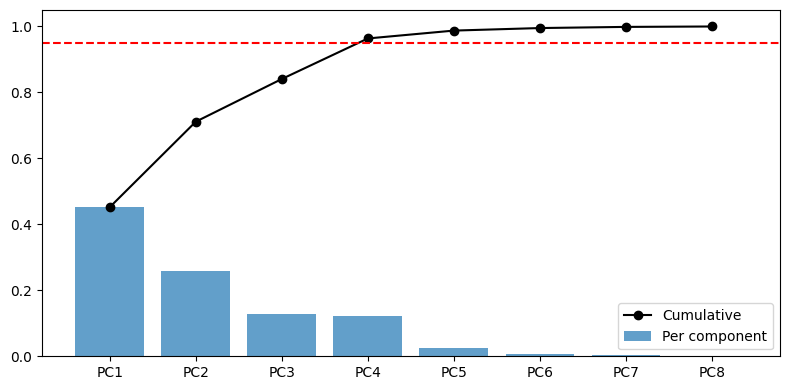

In [105]:
#Chart of the Explained Variance ( Scree Plot )
plt.figure(figsize=(8, 4))
plt.bar(explained.index, explained['explained_variance_ratio'], alpha=0.7, label='Per component')
plt.plot(explained.index, explained['cumulative'], 'o-', color='black', label='Cumulative')
plt.axhline(0.95, color='red', linestyle='--')
plt.legend()
plt.tight_layout()
plt.show()

In [106]:
#Metrics ( Reconstruction Error and Model Performance by Number of Components )
rows = {}
for k in range(1, len(sel_cols) + 1):
    pca_k = PCA(n_components=k).fit(scaled_pca)
    rows[k] = {'reconstruction_MSE': np.mean((scaled_pca - pca_k.inverse_transform(pca_k.transform(scaled_pca))) ** 2),
               'AUC': cross_val_score(make_pipeline(StandardScaler(), PCA(n_components=k), LogisticRegression(max_iter=1000)), X_sel, y_sel, cv=cv, scoring='roc_auc').mean()}
pd.DataFrame(rows).T.round(4)

,reconstruction_MSE,AUC
1,0.5481,0.7105
2,0.2887,0.9596
3,0.1592,0.9792
4,0.0363,0.9881
5,0.0124,0.9884
6,0.0047,0.9884
7,0.0012,0.9888
8,0.0000,0.9897


### **12. Full Pipeline Without Leakage**

All the steps together in **one object**. Every step is learned only with the train data of each fold, so the cross-validated score is honest. The same pipeline can be saved and applied to new data.

| Step | What it does |
|---|---|
| Negative values | Invalid values become null |
| Ratio | Creates `loan_to_income` |
| Numeric attributes | Median imputation + `RobustScaler` |
| Bins | Median imputation + `KBinsDiscretizer` ( ordinal, quartiles ) |
| Nominal attribute | Most frequent imputation + one-hot ( dummies ) |
| Model | Logistic regression with class weights |

In [107]:
#Create the Raw Dataframe for the Pipeline ( Original Attributes + the Nominal Attribute )
df_raw = df.copy()
df_raw['region'] = df_fe['region']
X_raw = df_raw[['income', 'age', 'loan', 'region']]
y_raw = df_raw['result']
print(X_raw.isnull().sum().to_dict(), '| Negative ages:', int((X_raw['age'] < 0).sum()))

{'income': 0, 'age': 3, 'loan': 0, 'region': 0} | Negative ages: 3


In [108]:
#Create the Functions of the Pipeline
def negatives_to_nan(data):
    out = data.copy()
    for col in ['income', 'age', 'loan']:
        out.loc[out[col] < 0, col] = np.nan
    return out

def add_ratio(data):
    out = data.copy()
    out['loan_to_income'] = out['loan'] / out['income']
    return out

In [109]:
#Create the Pipeline
numeric_features = ['income', 'age', 'loan', 'loan_to_income']
preprocessor = ColumnTransformer([
    ('numeric', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', RobustScaler())]), numeric_features),
    ('bins', Pipeline([('imputer', SimpleImputer(strategy='median')), ('binner', KBinsDiscretizer(n_bins=4, encode='ordinal', strategy='quantile'))]), ['age', 'income']),
    ('nominal', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), ['region'])])

full_pipeline = Pipeline([('fix_negatives', FunctionTransformer(negatives_to_nan)),
                          ('ratio', FunctionTransformer(add_ratio)),
                          ('preprocess', preprocessor),
                          ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))])
full_pipeline

Pipeline(steps=[('fix_negatives',
                 FunctionTransformer(func=<function negatives_to_nan at 0x7ca91a1a9b20>)),
                ('ratio',
                 FunctionTransformer(func=<function add_ratio at 0x7ca91a1a9940>)),
                ('preprocess',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   RobustScaler())]),
                                                  ['income', 'age', 'loan',
                                                   'loan_...
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('binner',
                                                                   KBinsDiscretizer(encode='ordinal',
                                                                                    n_bins=4))]),
                                                  ['age', 'income']),
                                                 ('nominal',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['region'])])),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

In [110]:
#Evaluate the Pipeline vs a Baseline ( Only Median Imputation and No Other Preprocessing )
scoring = ['accuracy', 'balanced_accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'average_precision']
baseline = Pipeline([('imputer', SimpleImputer(strategy='median')), ('model', LogisticRegression(max_iter=1000))])

rows = {}
for name, model, data in [('Baseline ( raw numeric attributes )', baseline, X_raw[num_cols]), ('Full pipeline', full_pipeline, X_raw)]:
    result = cross_validate(model, data, y_raw, cv=cv, scoring=scoring)
    rows[name] = {metric: result[f'test_{metric}'].mean() for metric in scoring}
    rows[name]['roc_auc_std'] = result['test_roc_auc'].std(ddof=1)
pd.DataFrame(rows).T.round(4)

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision,roc_auc_std
Baseline ( raw numeric attributes ),0.9445,0.8716,0.8250,0.7700,0.7960,0.9817,0.8787,0.0030
Full pipeline,0.9270,0.9383,0.6714,0.9541,0.7877,0.9847,0.9222,0.0041


In [111]:
#Fit with the Train Data and Transform the Train and the Test
X_train, X_test, y_train, y_test = train_test_split(X_raw, y_raw, test_size=0.25, random_state=SEED, stratify=y_raw)
full_pipeline.fit(X_train, y_train)
processed_train = full_pipeline[:-1].transform(X_train)
processed_test = full_pipeline[:-1].transform(X_test)
feature_names = full_pipeline.named_steps['preprocess'].get_feature_names_out()
print(processed_train.shape, processed_test.shape)
print(list(feature_names))

(1500, 11) (500, 11)
['numeric__income', 'numeric__age', 'numeric__loan', 'numeric__loan_to_income', 'bins__age', 'bins__income', 'nominal__region_Central', 'nominal__region_East', 'nominal__region_North', 'nominal__region_South', 'nominal__region_West']


In [112]:
#Metrics ( Checks of the Processed Data: Everything Must be True )
checks = {'no null values in train and test': not (np.isnan(processed_train).any() or np.isnan(processed_test).any()),
          'all values numeric ( float )': processed_train.dtype.kind == 'f',
          'train and test have the same columns': processed_train.shape[1] == processed_test.shape[1],
          'scaled numeric attributes centered in the median ( train )': bool(np.abs(np.median(processed_train[:, :4], axis=0)).max() < 1e-9),
          'dummies sum 1 per row': bool(np.allclose(processed_train[:, -5:].sum(axis=1), 1))}
pd.Series(checks, name='passed')

,passed
no null values in train and test,True
all values numeric ( float ),True
train and test have the same columns,True
scaled numeric attributes centered in the median ( train ),True
dummies sum 1 per row,True


In [113]:
#Metrics ( Final Evaluation in the Test Set )
proba = full_pipeline.predict_proba(X_test)[:, 1]
print(pd.Series(classification_metrics(y_test, (proba >= 0.5).astype(int), proba)).round(4))

accuracy             0.9260
balanced_accuracy    0.9334
precision            0.6700
recall               0.9437
f1                   0.7836
roc_auc              0.9821
pr_auc               0.9080
mcc                  0.7563
dtype: float64


In [114]:
#Save the Processed Dataset ( Attention! For Modeling, Always Use the Pipeline Inside the Cross-Validation: This File is Only for Inspection )
processed = pd.DataFrame(full_pipeline[:-1].fit_transform(X_raw), columns=feature_names)
processed['result'] = y_raw.values
processed.to_csv('credit_data_processed.csv', index=False)
print(processed.shape)

#Download the File ( Google Colab )
# from google.colab import files
# files.download('credit_data_processed.csv')

(2000, 12)


### **13. Summary of the Metrics**

| Task | Metrics used to measure the quality |
|---|---|
| Inspection | Null cells, negative values, duplicated rows, invalid ranges, skewness, memory |
| Data types | Memory saved, maximum relative error of the conversion |
| Negative values | Rows changed, mean / standard deviation, KS vs the valid values, class balance |
| Null values | RMSE and MAE vs the hidden true value, KS, std ratio, correlation gap |
| Outliers | Outliers per method, agreement ( Jaccard ), default rate of the outliers, skewness, kurtosis |
| Feature engineering | Mutual information and Spearman with the result ( with a random attribute as a sanity check ) |
| Categorical values | Cardinality, Cramer's V, mutual information, columns created, matrix rank, cross-validated AUC |
| Scaling | Mean / std / min / max, reversibility, skewness and normality, sensitivity to outliers, model AUC |
| Imbalanced classes | Recall, precision, F1, balanced accuracy, ROC AUC, PR AUC, MCC, confusion matrix |
| Feature selection | Variance, correlation, VIF, F-test, mutual information, performance by number of attributes |
| PCA | Explained variance, reconstruction error, performance by number of components |
| Pipeline | Cross-validated metrics ( mean and std ), checks of the processed data |

In [115]:
#Final Quality Report ( Raw vs Clean vs Feature Engineered: the Categorical Attributes Still Need Encoding )
pd.concat([report_raw, quality_report(df_clean, 'clean'), quality_report(df_fe, 'feature engineered')], axis=1)

,raw,clean,feature engineered
rows,2000.00,2000.00,2000.00
columns,5.00,5.00,15.00
null_cells,3.00,0.00,0.00
null_%,0.03,0.00,0.00
negative_values,3.00,0.00,998.00
duplicated_rows ( ignoring id ),0.00,0.00,0.00
non_numeric_columns,0.00,0.00,4.00
max_abs_skewness,2.06,2.06,2.06
memory_kb,78.30,78.30,284.20
